# Telecom-Churn-Revenue-Risk-Engine
**Author:** Andres Ruz Teran 
**Course:** GCI World Data Science Program, The University of Tokyo  
**Date:** November 25, 2026

## 1. Market Analysis and Problem Formulation

### 1.1 Telecommunications Market Context
In mature wireless markets such as the United States, mobile connection penetration exceeds **100%** of the population, creating a saturated competitive landscape where subscriber growth is largely a zero sum contest [1, 2]. Industry benchmarks place blended monthly wireless churn around **1.5% to 2.2%** (roughly 18% to 24% annualized) [2, 3], whereas **Subscriber Acquisition Cost (SAC)** averages between **$350 and $500** per gross addition compared with **$15 to $30** for targeted retention outreach. That represents more than a tenfold cost asymmetry.

For **Company A**, preserving recurring Average Revenue Per User (ARPU) and extending customer lifetime is far more capital efficient than replacing departed accounts. *Success means creating more business value than the proposal costs to implement.*

### 1.2 Problem Definition
| Dimension | Specification |
| :--- | :--- |
| **Business Objective** | Reduce preventable subscriber attrition and maximize net preserved gross margin across Company A's 100,000 account base. |
| **Business Decision** | Identify which subscribers warrant proactive retention outreach each month and select the operational action (device upgrade, plan adjustment, or network support) that addresses their primary risk driver. |
| **Target Definition** | Binary `churn` indicator observed in the **31 to 60 day forward window** after observation (one month horizon). |
| **ML Task and Decision Rule** | Supervised probability estimation combined with **Bayes prior shift calibration** (to 2.0% monthly churn [4]) and **Expected Value at Risk (VaR)** prioritization ($\text{EV}_i = P_{\text{real}}(\text{churn}_i) \cdot S \cdot V_i - C > 0$). |

In [1]:
# 2. Environment Configuration & Deterministic Setup
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Scikit-learn preprocessing, validation, and metrics
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

# Gradient boosted tree models
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10

pd.set_option('display.max_columns', 120)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

## 2. Google Drive Connection and Data Ingestion

When running in Google Colab, the cell below mounts Google Drive so the notebook can locate the `telecom` folder inside `MyDrive` (following the course tutorial setup). When running locally, it skips the Colab mount automatically and resolves the relative dataset directory.

The dataset is organized across two relational tables that share `Customer_ID` as a unique primary key:
1. `Client.csv` (100,000 rows by 50 columns): Account tenure, credit class, handset attributes, and household demographics.
2. `Record.csv` (100,000 rows by 51 columns): Mean monthly usage, overage charges, call failure telemetry, and the target `churn`.

We perform a strict inner join on `Customer_ID` and verify row counts, uniqueness, and target completeness before running any exploration.

In [2]:
# 2.1 Connect to Google Drive (only when running inside Google Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    print("Google Drive mounted at /content/drive.")
except ImportError:
    IN_COLAB = False
    print("Local execution detected (skipping Google Drive mount).")

# 2.2 Portable data path resolution (Colab Drive, local repo, nested folder, or EntregaFinal)
base_dir = Path.cwd()
search_paths = [
    base_dir / "telecom",
    base_dir / "Final Assignment" / "telecom",
    base_dir.parent / "telecom",
    base_dir.parent / "Final Assignment" / "telecom",
    Path("/content/drive/MyDrive/Final Assignment/telecom"),
    Path("/content/drive/MyDrive/Final Assignment/Final Assignment/telecom"),
    Path("/content/drive/MyDrive/telecom"),
]
telecom_dir = next((p for p in search_paths if p.exists()), None)

# Fallback search up to 3 levels inside Google Drive if placed in a custom folder
if telecom_dir is None and IN_COLAB and Path("/content/drive/MyDrive").exists():
    for candidate in Path("/content/drive/MyDrive").glob("**/Client.csv"):
        if len(candidate.relative_to("/content/drive/MyDrive").parts) <= 4:
            telecom_dir = candidate.parent
            break

if telecom_dir is None:
    raise FileNotFoundError(
        "Could not locate 'telecom/' folder containing Client.csv and Record.csv. "
        "Upload 'Final Assignment' to Google Drive MyDrive or place 'telecom/' in the working directory."
    )

client = pd.read_csv(telecom_dir / "Client.csv")
record = pd.read_csv(telecom_dir / "Record.csv")

# 1:1 inner join on primary key Customer_ID
df = record.merge(client, on='Customer_ID', how='inner')

# Integrity assertions
assert df.shape == (100000, 100), f"Unexpected merged shape: {df.shape}"
assert df['Customer_ID'].nunique() == 100000, "Duplicate Customer_ID detected."
assert df.duplicated().sum() == 0, "Duplicate rows detected."
assert df['churn'].isnull().sum() == 0, "Missing values found in target 'churn'."

print(f"Data source resolved: {telecom_dir.name}/")
print(f"Client table : {client.shape[0]:,} rows x {client.shape[1]} cols")
print(f"Record table : {record.shape[0]:,} rows x {record.shape[1]} cols")
print(f"Merged ABT   : {df.shape[0]:,} rows x {df.shape[1]} cols (0 duplicates, 0 missing targets)")
df.head(3)

Local execution detected (skipping Google Drive mount).


Data source resolved: telecom/
Client table : 100,000 rows x 50 cols
Record table : 100,000 rows x 51 cols
Merged ABT   : 100,000 rows x 100 cols (0 duplicates, 0 missing targets)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.997,219.250,22.500,0.247,0.000,0.000,0.000,0.000,0.000,-157.250,-18.997,0.667,0.000,0.667,0.000,6.333,0.000,52.333,0.000,42.333,0.000,45.000,0.000,0.000,0.000,0.000,18.000,0.000,90.643,0.000,97.177,0.000,0.000,0.000,0.000,58.000,0.000,132.600,0.000,24.000,0.000,55.220,0.000,1.333,52.333,45.000,0.000,0.333,1,61,1000001,2,1,U,A,N,1652,4228.000,1504.620,1453.440,4085.000,1602,29.660,83.370,32.690,272,116,30,322.000,136.000,38.000,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.990,2.000,2.000,WCMB,0.000,0.000,O,15.000,S,S,1.000,M,4.000,3.000,C,A,0.000,N,U,U,U,U,U,Y,361.000
1,57.492,482.750,37.425,0.247,22.750,9.100,9.100,0.000,0.000,532.250,50.987,8.333,0.000,1.000,0.000,61.333,0.000,263.333,0.000,69.000,0.000,193.333,0.000,1.667,6.333,5.463,53.000,0.333,189.397,0.000,55.280,46.333,24.217,6.333,3.697,83.667,0.000,75.333,0.000,157.000,0.000,169.343,0.000,9.333,263.333,193.333,0.000,5.667,0,56,1000002,1,1,N,EA,N,14654,26400.000,2851.680,2833.880,26367.000,14624,51.530,479.400,265.890,305,158,40,477.000,275.000,48.000,U,CHICAGO AREA,N,N,NaN,7.000,6.000,WC,1.000,1.000,NaN,1.000,S,S,1.000,M,5.000,1.000,C,A,0.000,Z,U,U,U,U,U,Y,240.000
2,16.990,10.250,16.990,0.000,0.000,0.000,0.000,0.000,0.000,-4.250,0.000,0.333,0.000,0.000,0.000,2.667,0.000,9.000,0.000,0.333,0.000,6.000,0.000,0.000,0.000,0.000,0.333,0.000,5.427,0.000,0.000,0.000,0.000,0.000,0.000,5.000,0.000,5.193,0.000,1.000,0.000,0.233,0.000,0.333,9.000,6.000,0.000,0.000,1,58,1000003,1,1,Y,C,N,7903,24385.053,2155.910,1934.470,24303.050,7888,34.540,433.980,140.860,12,7,17,11.000,6.000,17.000,S,GREAT LAKES AREA,N,N,29.990,2.000,1.000,NaN,0.000,0.000,O,7.000,S,M,2.000,M,5.000,2.000,C,A,0.000,N,U,Y,U,U,U,Y,1504.000


## 3. Data Quality Audit and Exploratory Data Analysis

Before building predictive models, we examine four foundational properties of the dataset:
1. **Sampling Design and Class Balance:** Confirming why the near 50/50 split reflects retrospective sampling rather than the real world monthly wireless churn rate near 2.0%.
2. **Missingness and Invalid Records:** Identifying sparse demographic fields alongside negative equipment ages (`eqpdays < 0`) and billing credit adjustments.
3. **Hardware and Billing Pain Points:** Quantifying churn concentration past the one year handset mark and among accounts exposed to overage billing spikes.
4. **Network Friction and Usage Velocity:** Isolating call failure confounding caused by dormant zero attempt subscribers and measuring churn elevation when recent three month usage falls below six month baselines.

=== DATA QUALITY & ANOMALY AUDIT ===
* Negative eqpdays (< 0 days) : 133 rows (min = -5), clipped to 0 before feature engineering.
* Negative rev_Mean (< $0)    : 5 rows (min = $-6.17), reflecting billing credit adjustments.
* Negative totmrc_Mean (< $0) : 23 rows (min = $-26.91), reflecting plan credit adjustments.
* Columns with >30% missing   : 6 demographic/household fields (handled natively by trees, imputed for linear models).


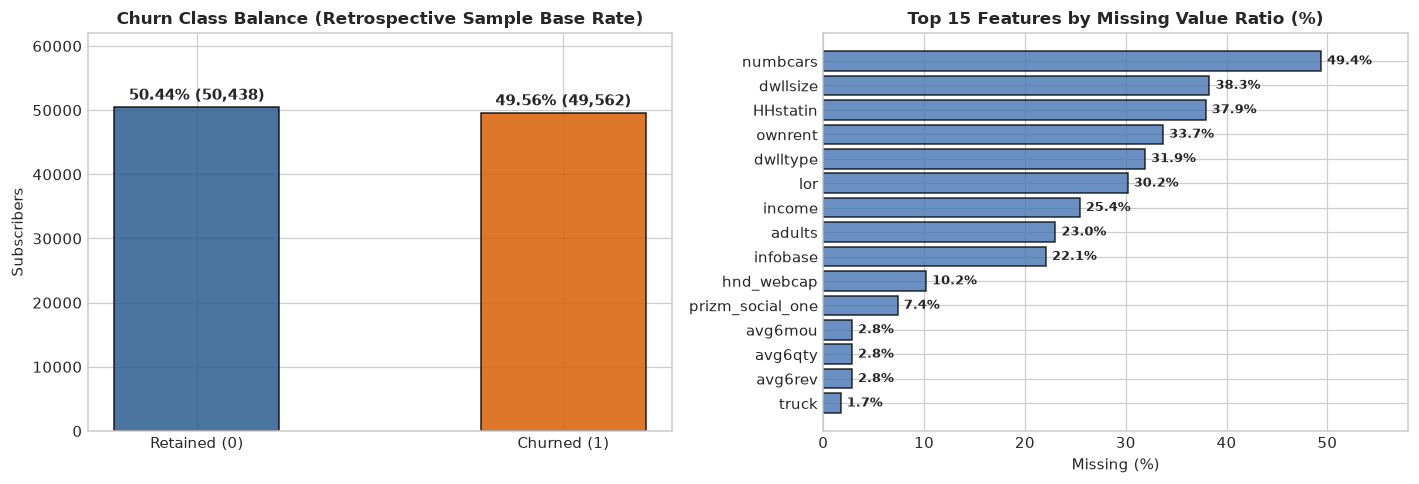


Sampling Design Note: Sample churn rate is 49.56% due to retrospective sampling [1].
Because true US wireless monthly churn is ~2.0%, Section 8 applies Bayes prior calibration before financial optimization.


In [3]:
# 3.1 Data Quality Audit, Target Balance & Missingness Profile
neg_eqp = int((df['eqpdays'] < 0).sum())
neg_rev = int((df['rev_Mean'] < 0).sum())
neg_mrc = int((df['totmrc_Mean'] < 0).sum())
sample_churn_rate = df['churn'].mean()

print("=== DATA QUALITY & ANOMALY AUDIT ===")
print(f"* Negative eqpdays (< 0 days) : {neg_eqp:,} rows (min = {df['eqpdays'].min():.0f}), clipped to 0 before feature engineering.")
print(f"* Negative rev_Mean (< $0)    : {neg_rev:,} rows (min = ${df['rev_Mean'].min():.2f}), reflecting billing credit adjustments.")
print(f"* Negative totmrc_Mean (< $0) : {neg_mrc:,} rows (min = ${df['totmrc_Mean'].min():.2f}), reflecting plan credit adjustments.")
print(f"* Columns with >30% missing   : {int((df.isnull().mean() > 0.30).sum())} demographic/household fields (handled natively by trees, imputed for linear models).")

# Clean invalid negative equipment age prior to behavioral plots
df['eqpdays'] = df['eqpdays'].clip(lower=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Target distribution
counts = df['churn'].value_counts().sort_index()
props = df['churn'].value_counts(normalize=True).sort_index() * 100
colors = ['#2b5c8f', '#d95f02']

bars = axes[0].bar(['Retained (0)', 'Churned (1)'], counts.values, color=colors, width=0.45, edgecolor='black', alpha=0.85)
axes[0].set_title('Churn Class Balance (Retrospective Sample Base Rate)')
axes[0].set_ylabel('Subscribers')
for b, p in zip(bars, props.values):
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 1200, f'{p:.2f}% ({int(b.get_height()):,})',
                 ha='center', fontweight='bold', fontsize=9.5)
axes[0].set_ylim(0, 62000)

# Top 15 missing features
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False).head(15)
axes[1].barh(missing_pct.index[::-1], missing_pct.values[::-1], color='#4575b4', edgecolor='black', alpha=0.8)
axes[1].set_title('Top 15 Features by Missing Value Ratio (%)')
axes[1].set_xlabel('Missing (%)')
for i, v in enumerate(missing_pct.values[::-1]):
    axes[1].text(v + 0.6, i, f'{v:.1f}%', va='center', fontsize=8.5, fontweight='bold')
axes[1].set_xlim(0, 58)

plt.tight_layout()
plt.show()

print(f"\nSampling Design Note: Sample churn rate is {sample_churn_rate:.2%} due to retrospective sampling [1].")
print("Because true US wireless monthly churn is ~2.0%, Section 8 applies Bayes prior calibration before financial optimization.")

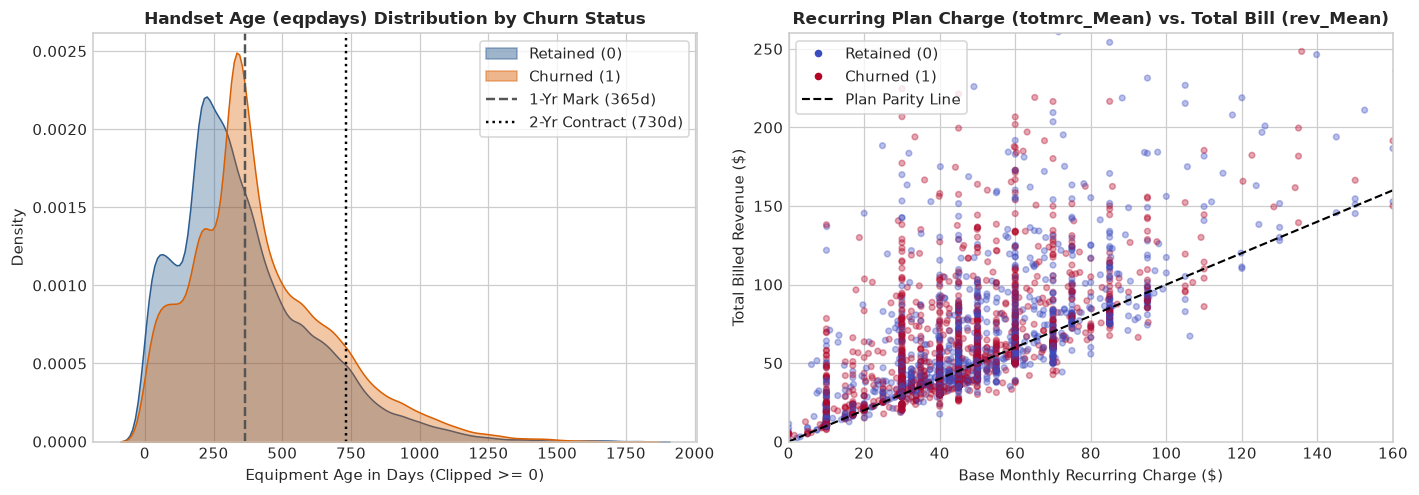

Key EDA Takeaways:
1. Handset Cliff: Subscribers with eqpdays > 365 churn at 54.8% vs. 45.2% for newer devices (+9.6 pp).
2. Bill Shock: Accounts with >15% overage revenue share churn at 51.6% vs. 48.5% (+3.1 pp).


In [4]:
# 3.2 Handset Upgrade Cliff & Billing Friction Diagnostics
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# Equipment age density: stayers vs churners (with explicit legend handles)
sns.kdeplot(data=df[df['churn'] == 0], x='eqpdays', fill=True, color='#2b5c8f', alpha=0.35, ax=axes[0], legend=False)
sns.kdeplot(data=df[df['churn'] == 1], x='eqpdays', fill=True, color='#d95f02', alpha=0.35, ax=axes[0], legend=False)
axes[0].axvline(365, color='#555555', linestyle='--', linewidth=1.6)
axes[0].axvline(730, color='black', linestyle=':', linewidth=1.6)
axes[0].set_title('Handset Age (eqpdays) Distribution by Churn Status')
axes[0].set_xlabel('Equipment Age in Days (Clipped >= 0)')
axes[0].set_ylabel('Density')

custom_handles = [
    Patch(facecolor='#2b5c8f', alpha=0.45, edgecolor='#2b5c8f', label='Retained (0)'),
    Patch(facecolor='#d95f02', alpha=0.45, edgecolor='#d95f02', label='Churned (1)'),
    Line2D([0], [0], color='#555555', linestyle='--', linewidth=1.6, label='1-Yr Mark (365d)'),
    Line2D([0], [0], color='black', linestyle=':', linewidth=1.6, label='2-Yr Contract (730d)')
]
axes[0].legend(handles=custom_handles, loc='upper right', frameon=True)

# Revenue friction: recurring plan fee vs actual monthly bill
sample_df = df.sample(3500, random_state=RANDOM_SEED)
axes[1].scatter(sample_df['totmrc_Mean'], sample_df['rev_Mean'], c=sample_df['churn'], cmap='coolwarm', alpha=0.35, s=14)
axes[1].plot([0, 160], [0, 160], 'k--', linewidth=1.4, label='Plan Parity (Zero Overages)')
axes[1].set_xlim(0, 160)
axes[1].set_ylim(0, 260)
axes[1].set_title('Recurring Plan Charge (totmrc_Mean) vs. Total Bill (rev_Mean)')
axes[1].set_xlabel('Base Monthly Recurring Charge ($)')
axes[1].set_ylabel('Total Billed Revenue ($)')
scatter_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#3b4cc0', markersize=6, label='Retained (0)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#b40426', markersize=6, label='Churned (1)'),
    Line2D([0], [0], color='k', linestyle='--', linewidth=1.4, label='Plan Parity Line')
]
axes[1].legend(handles=scatter_handles, loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

churn_le365 = df.loc[df['eqpdays'] <= 365, 'churn'].mean()
churn_gt365 = df.loc[df['eqpdays'] > 365, 'churn'].mean()
overage_ratio_tmp = np.where(df['rev_Mean'] > 0, df['ovrrev_Mean'] / df['rev_Mean'], 0.0)
churn_hi_ovr = df.loc[overage_ratio_tmp > 0.15, 'churn'].mean()
churn_lo_ovr = df.loc[overage_ratio_tmp <= 0.15, 'churn'].mean()

print("Key EDA Takeaways:")
print(f"1. Handset Cliff: Subscribers with eqpdays > 365 churn at {churn_gt365:.1%} vs. {churn_le365:.1%} for newer devices (+{(churn_gt365 - churn_le365)*100:.1f} pp).")
print(f"2. Bill Shock: Accounts with >15% overage revenue share churn at {churn_hi_ovr:.1%} vs. {churn_lo_ovr:.1%} (+{(churn_hi_ovr - churn_lo_ovr)*100:.1f} pp).")

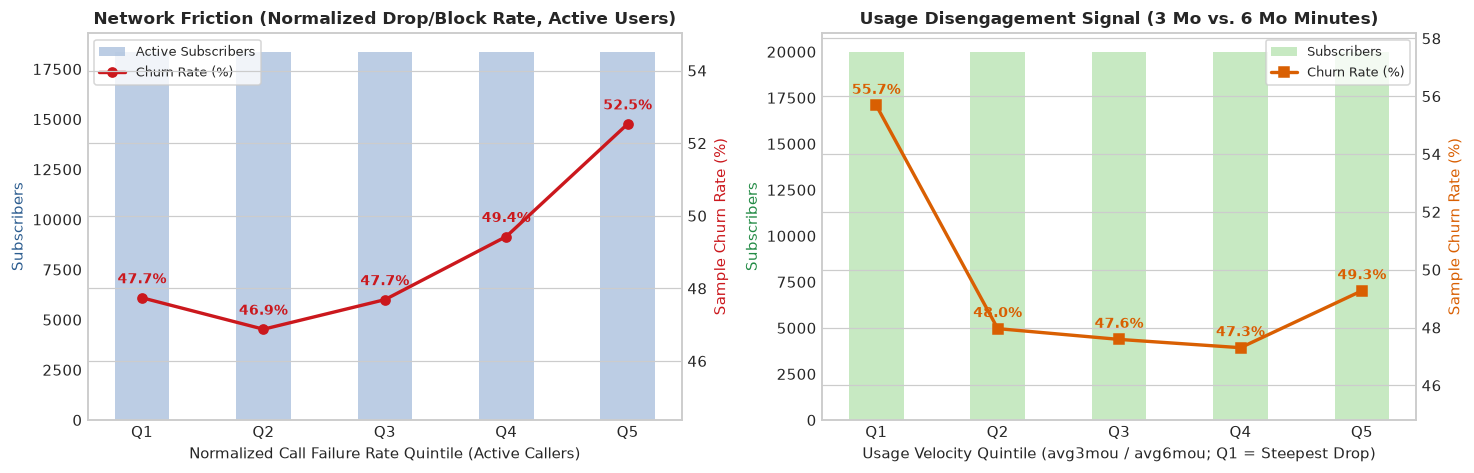

Confounding Audit: Dormant zero-attempt accounts (n=8,160) churn at 57.5%, which masks raw drop counts.
Normalized Network Friction (active callers): Churn rises from 47.7% (Q1) to 52.5% (Q5, +4.8 pp).
Usage Disengagement (3m/6m ratio): Steepest usage drop quintile (Q1) churns at 55.7% vs. 47.6% in stable Q3 (+8.1 pp).


In [5]:
# 3.3 Network Failure Confounding vs. Normalized Failure Rate & Usage Disengagement
active_mask = df['attempt_Mean'] > 0
active_df = df.loc[active_mask].copy()
active_df['drop_fail_rate'] = active_df['drop_blk_Mean'] / active_df['attempt_Mean']
active_df['dfr_quintile'] = pd.qcut(active_df['drop_fail_rate'].fillna(0), q=5, duplicates='drop')
dfr_churn = active_df.groupby('dfr_quintile', observed=True)['churn'].agg(['count', 'mean']).reset_index()

mou_vel = np.where(df['avg6mou'] > 0, df['avg3mou'] / (df['avg6mou'] + 1.0), 1.0)
df['mou_vel_q'] = pd.qcut(mou_vel, q=5, duplicates='drop')
vel_churn = df.groupby('mou_vel_q', observed=True)['churn'].agg(['count', 'mean']).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))

# Left: Active-user normalized call failure rate quintiles
ax1 = axes[0]
ax1_t = ax1.twinx()
ax1.bar(range(len(dfr_churn)), dfr_churn['count'], color='#a6bddb', alpha=0.75, width=0.45, label='Active Subscribers')
ax1_t.plot(range(len(dfr_churn)), dfr_churn['mean'] * 100, color='#cb181d', marker='o', linewidth=2.2, label='Churn Rate (%)')
ax1.set_xticks(range(len(dfr_churn)))
ax1.set_xticklabels([f'Q{i+1}' for i in range(len(dfr_churn))])
ax1.set_xlabel('Normalized Call Failure Rate Quintile (Active Callers)')
ax1.set_ylabel('Subscribers', color='#2b5c8f')
ax1_t.set_ylabel('Sample Churn Rate (%)', color='#cb181d')
ax1.set_title('Network Friction (Normalized Drop/Block Rate, Active Users)')
ax1.grid(False)
ax1_t.set_ylim(dfr_churn['mean'].min()*100 - 2.5, dfr_churn['mean'].max()*100 + 2.5)
for i, rate in enumerate(dfr_churn['mean'] * 100):
    ax1_t.text(i, rate + 0.4, f'{rate:.1f}%', ha='center', color='#cb181d', fontweight='bold', fontsize=9)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax1_t.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=8.5, frameon=True)

# Right: Usage velocity (3m vs 6m) quintiles
ax2 = axes[1]
ax2_t = ax2.twinx()
ax2.bar(range(len(vel_churn)), vel_churn['count'], color='#bae4b3', alpha=0.8, width=0.45, label='Subscribers')
ax2_t.plot(range(len(vel_churn)), vel_churn['mean'] * 100, color='#d95f02', marker='s', linewidth=2.2, label='Churn Rate (%)')
ax2.set_xticks(range(len(vel_churn)))
ax2.set_xticklabels([f'Q{i+1}' for i in range(len(vel_churn))])
ax2.set_xlabel('Usage Velocity Quintile (avg3mou / avg6mou; Q1 = Steepest Drop)')
ax2.set_ylabel('Subscribers', color='#238b45')
ax2_t.set_ylabel('Sample Churn Rate (%)', color='#d95f02')
ax2.set_title('Usage Disengagement Signal (3 Mo vs. 6 Mo Minutes)')
ax2.grid(False)
ax2_t.set_ylim(vel_churn['mean'].min()*100 - 2.5, vel_churn['mean'].max()*100 + 2.5)
for i, rate in enumerate(vel_churn['mean'] * 100):
    ax2_t.text(i, rate + 0.4, f'{rate:.1f}%', ha='center', color='#d95f02', fontweight='bold', fontsize=9)
h3, l3 = ax2.get_legend_handles_labels()
h4, l4 = ax2_t.get_legend_handles_labels()
ax2.legend(h3 + h4, l3 + l4, loc='upper right', fontsize=8.5, frameon=True)

plt.tight_layout()
plt.show()

dormant_rate = df.loc[~active_mask, 'churn'].mean()
dfr_q1, dfr_q5 = dfr_churn['mean'].iloc[0], dfr_churn['mean'].iloc[-1]
vel_q1, vel_q3 = vel_churn['mean'].iloc[0], vel_churn['mean'].iloc[2]
print(f"Confounding Audit: Dormant zero-attempt accounts (n={(~active_mask).sum():,}) churn at {dormant_rate:.1%}, which masks raw drop counts.")
print(f"Normalized Network Friction (active callers): Churn rises from {dfr_q1:.1%} (Q1) to {dfr_q5:.1%} (Q5, +{(dfr_q5 - dfr_q1)*100:.1f} pp).")
print(f"Usage Disengagement (3m/6m ratio): Steepest usage drop quintile (Q1) churns at {vel_q1:.1%} vs. {vel_q3:.1%} in stable Q3 (+{(vel_q1 - vel_q3)*100:.1f} pp).")
df.drop(columns=['mou_vel_q'], inplace=True, errors='ignore')

## 4. Feature Engineering and Leakage Free Preprocessing

We construct eight domain signals capturing usage momentum, device aging, and service friction from raw telemetry:
1. `eqp_tenure_ratio`: Handset age relative to customer tenure ($\text{eqpdays} / (\text{months} \times 30.4375 + 1)$).
2. `mou_trend_3_vs_6` and `mou_trend_3_vs_life`: Short term three month usage divided by six month and lifetime averages, where values below 1.0 signal declining engagement.
3. `rev_trend_3_vs_6`: Recent three month versus six month billing velocity.
4. `drop_failure_rate` and `completion_rate`: Call drop/block failure and completion rates normalized by attempted calls.
5. `overage_rev_ratio`: Share of monthly bill driven by overage charges.
6. `custcare_rate`: Customer care escalation intensity relative to call volume.

### Categorical Encoding Strategy
Nominal fields (`area`, `crclscod`, `ethnic`, `marital`, `dwlltype`, and related attributes) have no natural numerical order. For LightGBM and XGBoost, missing values are labeled `'Missing'` and passed as native `category` dtypes (`enable_categorical=True` in XGBoost). For Logistic Regression, preprocessing runs strictly inside a `sklearn.pipeline.Pipeline` using median imputation, standardization, and `OneHotEncoder(handle_unknown='ignore', min_frequency=50)` fit on training folds only.

In [6]:
# Construct domain features with safe division
df_feat = df.copy()

# Hardware obsolescence relative to tenure
df_feat['eqp_tenure_ratio'] = df_feat['eqpdays'] / (df_feat['months'] * 30.4375 + 1.0)

# Usage & billing momentum ratios
df_feat['mou_trend_3_vs_6'] = np.where(df_feat['avg6mou'] > 0, df_feat['avg3mou'] / (df_feat['avg6mou'] + 1.0), 1.0)
df_feat['rev_trend_3_vs_6'] = np.where(df_feat['avg6rev'] > 0, df_feat['avg3rev'] / (df_feat['avg6rev'] + 1.0), 1.0)
df_feat['mou_trend_3_vs_life'] = np.where(df_feat['avgmou'] > 0, df_feat['avg3mou'] / (df_feat['avgmou'] + 1.0), 1.0)

# Network quality & billing/support friction ratios
df_feat['drop_failure_rate'] = np.where(df_feat['attempt_Mean'] > 0, df_feat['drop_blk_Mean'] / (df_feat['attempt_Mean'] + 1.0), 0.0)
df_feat['completion_rate'] = np.where(df_feat['attempt_Mean'] > 0, df_feat['complete_Mean'] / (df_feat['attempt_Mean'] + 1.0), 1.0)
df_feat['overage_rev_ratio'] = np.where(df_feat['rev_Mean'] > 0, df_feat['ovrrev_Mean'] / (df_feat['rev_Mean'] + 1.0), 0.0)
df_feat['custcare_rate'] = np.where(df_feat['totcalls'] > 0, df_feat['custcare_Mean'] / (df_feat['totcalls'] / (df_feat['months'] + 1.0) + 1.0), 0.0)

df_feat.replace([np.inf, -np.inf], np.nan, inplace=True)

# Feature matrix & target
X_raw = df_feat.drop(columns=['Customer_ID', 'churn'])
y = df_feat['churn']

cat_cols = X_raw.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
num_cols = [c for c in X_raw.columns if c not in cat_cols]

# Native category matrix for LightGBM & XGBoost
X_tree = X_raw.copy()
for c in cat_cols:
    X_tree[c] = X_tree[c].fillna('Missing').astype('category')

# Stratified 75/25 Train / Holdout Test split
X_train_t, X_test_t, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.25, random_state=RANDOM_SEED, stratify=y
)
X_train_raw = X_raw.loc[X_train_t.index]
X_test_raw = X_raw.loc[X_test_t.index]

print(f"Engineered feature set : {X_raw.shape[1]} features ({len(num_cols)} numeric, {len(cat_cols)} categorical)")
print(f"Train partition        : {X_train_t.shape[0]:,} rows ({y_train.mean():.2%} positive)")
print(f"Holdout Test partition : {X_test_t.shape[0]:,} rows ({y_test.mean():.2%} positive)")

Engineered feature set : 106 features (85 numeric, 21 categorical)
Train partition        : 75,000 rows (49.56% positive)
Holdout Test partition : 25,000 rows (49.56% positive)


## 5. Model Benchmarking and Five Fold Cross Validation

We evaluate three distinct model architectures under identical **five fold stratified cross validation** across the 75,000 row training split before scoring the 25,000 row holdout test set once:
1. **Regularized Logistic Regression (L2 with One Hot Encoding):** Interpretable linear baseline.
2. **LightGBM Classifier (Native Categoricals):** Regularized histogram gradient boosting (`num_leaves=31`, `min_child_samples=50`, L1 and L2 penalties).
3. **XGBoost Classifier (Histogram with Native Categoricals):** Depth regularized gradient boosted trees (`max_depth=5`, `min_child_weight=10`).

Comparing Train CV AUC, Out of Fold (OOF) CV AUC, and Holdout Test AUC verifies generalization and confirms the absence of target leakage. Out of fold predictions also serve as our clean validation set for threshold tuning in Section 8.

In [7]:
# 5.1 Five-Fold Stratified Cross-Validation & Holdout Evaluation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

def make_lr_pipeline():
    pre = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='Missing')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore', min_frequency=50))]), cat_cols)
    ])
    return Pipeline([('prep', pre), ('clf', LogisticRegression(C=0.05, max_iter=1000, random_state=RANDOM_SEED))])

def make_lgb_model():
    return LGBMClassifier(
        n_estimators=400, learning_rate=0.03, num_leaves=31,
        min_child_samples=50, reg_alpha=0.5, reg_lambda=2.0,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=RANDOM_SEED, n_jobs=-1, verbose=-1
    )

def make_xgb_model():
    return XGBClassifier(
        n_estimators=400, learning_rate=0.03, max_depth=5,
        min_child_weight=10, reg_alpha=0.5, reg_lambda=2.0,
        subsample=0.8, colsample_bytree=0.8,
        enable_categorical=True, tree_method='hist',
        random_state=RANDOM_SEED, eval_metric='logloss', n_jobs=-1
    )

oof_probs = {
    'Logistic Regression (L2 + OHE)': np.zeros(len(X_train_t)),
    'LightGBM Classifier': np.zeros(len(X_train_t)),
    'XGBoost Classifier': np.zeros(len(X_train_t))
}
train_cv_aucs = {k: [] for k in oof_probs}

for tr_idx, va_idx in skf.split(X_train_t, y_train):
    y_tr_f, y_va_f = y_train.iloc[tr_idx], y_train.iloc[va_idx]

    # Logistic Regression fold
    lr_f = make_lr_pipeline()
    lr_f.fit(X_train_raw.iloc[tr_idx], y_tr_f)
    train_cv_aucs['Logistic Regression (L2 + OHE)'].append(roc_auc_score(y_tr_f, lr_f.predict_proba(X_train_raw.iloc[tr_idx])[:, 1]))
    oof_probs['Logistic Regression (L2 + OHE)'][va_idx] = lr_f.predict_proba(X_train_raw.iloc[va_idx])[:, 1]

    # LightGBM fold
    lgb_f = make_lgb_model()
    lgb_f.fit(X_train_t.iloc[tr_idx], y_tr_f)
    train_cv_aucs['LightGBM Classifier'].append(roc_auc_score(y_tr_f, lgb_f.predict_proba(X_train_t.iloc[tr_idx])[:, 1]))
    oof_probs['LightGBM Classifier'][va_idx] = lgb_f.predict_proba(X_train_t.iloc[va_idx])[:, 1]

    # XGBoost fold
    xgb_f = make_xgb_model()
    xgb_f.fit(X_train_t.iloc[tr_idx], y_tr_f)
    train_cv_aucs['XGBoost Classifier'].append(roc_auc_score(y_tr_f, xgb_f.predict_proba(X_train_t.iloc[tr_idx])[:, 1]))
    oof_probs['XGBoost Classifier'][va_idx] = xgb_f.predict_proba(X_train_t.iloc[va_idx])[:, 1]

# Fit final models on full 75k training set and score 25k holdout test set
lr_model = make_lr_pipeline().fit(X_train_raw, y_train)
lr_probs = lr_model.predict_proba(X_test_raw)[:, 1]

lgb_model = make_lgb_model().fit(X_train_t, y_train)
lgb_probs = lgb_model.predict_proba(X_test_t)[:, 1]

xgb_model = make_xgb_model().fit(X_train_t, y_train)
xgb_probs = xgb_model.predict_proba(X_test_t)[:, 1]

models = {
    'Logistic Regression (L2 + OHE)': lr_probs,
    'LightGBM Classifier': lgb_probs,
    'XGBoost Classifier': xgb_probs
}

print("Five-fold cross-validation and full-train holdout evaluation complete.")

Five-fold cross-validation and full-train holdout evaluation complete.


## 6. Quantitative Evaluation and Generalization Diagnostics

### Benchmarking Context (Neslin et al., 2006)
In academic benchmarks evaluating this Cell2Cell churn dataset (*Neslin et al., 2006, Journal of Marketing Research* [1]), leading modeling teams achieved ROC-AUC scores between **0.68 and 0.71**. Consumer churn in wireless services depends in part on unobserved external events such as localized competitor promotions, household moves, or device gifting. Consequently, any result above 0.85 on these features would indicate target leakage, and operational business impact comes from **decile risk concentration** and **calibrated probability lift**.

In [8]:
# 6.1 Formal Cross-Validation & Holdout Benchmark Table
records = []
for name, probs in models.items():
    preds = (probs >= 0.5).astype(int)
    records.append({
        'Model Architecture': name,
        'Train CV AUC': np.mean(train_cv_aucs[name]),
        'OOF CV AUC': roc_auc_score(y_train, oof_probs[name]),
        'Test ROC-AUC': roc_auc_score(y_test, probs),
        'Test PR-AUC': average_precision_score(y_test, probs),
        'Brier Score': brier_score_loss(y_test, probs),
        'Accuracy (@0.5)': accuracy_score(y_test, preds),
        'Precision (@0.5)': precision_score(y_test, preds),
        'Recall (@0.5)': recall_score(y_test, preds),
        'F1-Score (@0.5)': f1_score(y_test, preds)
    })

eval_df = pd.DataFrame(records)
print("=== MODEL BENCHMARK RESULTS (5-FOLD CV + HOLDOUT TEST SET) ===")
display(eval_df.style.format({
    'Train CV AUC': '{:.4f}', 'OOF CV AUC': '{:.4f}', 'Test ROC-AUC': '{:.4f}',
    'Test PR-AUC': '{:.4f}', 'Brier Score': '{:.4f}', 'Accuracy (@0.5)': '{:.4f}',
    'Precision (@0.5)': '{:.4f}', 'Recall (@0.5)': '{:.4f}', 'F1-Score (@0.5)': '{:.4f}'
}).highlight_max(subset=['OOF CV AUC', 'Test ROC-AUC', 'Test PR-AUC', 'Accuracy (@0.5)', 'F1-Score (@0.5)'], color='#c7e9c0')
  .highlight_min(subset=['Brier Score'], color='#c7e9c0'))

lgb_oof = roc_auc_score(y_train, oof_probs['LightGBM Classifier'])
lgb_test_auc = roc_auc_score(y_test, lgb_probs)
print(f"Generalization Check (LightGBM): OOF CV AUC = {lgb_oof:.4f} vs. Holdout Test AUC = {lgb_test_auc:.4f} (gap = {lgb_test_auc - lgb_oof:+.4f}).")

=== MODEL BENCHMARK RESULTS (5-FOLD CV + HOLDOUT TEST SET) ===


,Model Architecture,Train CV AUC,OOF CV AUC,Test ROC-AUC,Test PR-AUC,Brier Score,Accuracy (@0.5),Precision (@0.5),Recall (@0.5),F1-Score (@0.5)
0,Logistic Regression (L2 + OHE),0.6407,0.6339,0.6370,0.6118,0.2359,0.5994,0.5966,0.5921,0.5944
1,LightGBM Classifier,0.7848,0.6963,0.6985,0.6860,0.2196,0.6409,0.6350,0.6479,0.6414
2,XGBoost Classifier,0.7699,0.6945,0.6962,0.6842,0.2203,0.6410,0.6361,0.6446,0.6403


Generalization Check (LightGBM): OOF CV AUC = 0.6963 vs. Holdout Test AUC = 0.6985 (gap = +0.0022).


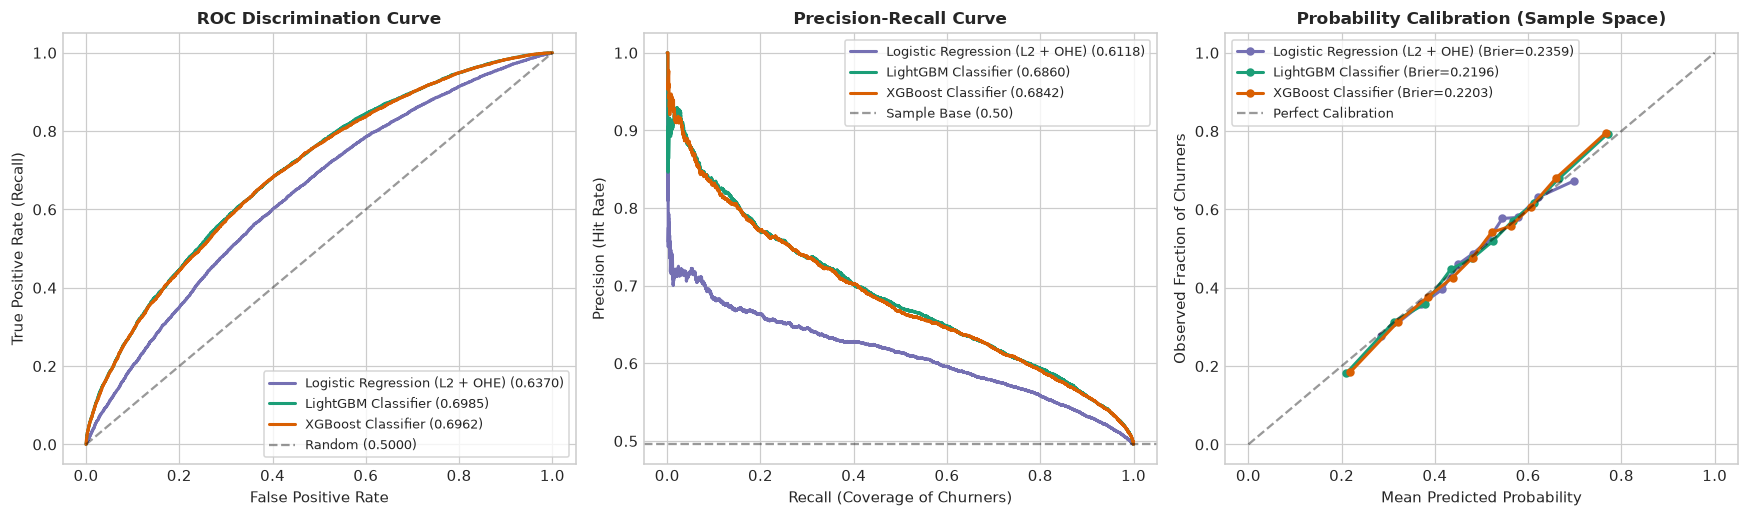

In [9]:
# 6.2 ROC, Precision-Recall, and Calibration Reliability Curves
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

palette = {
    'Logistic Regression (L2 + OHE)': '#7570b3',
    'LightGBM Classifier': '#1b9e77',
    'XGBoost Classifier': '#d95f02'
}

# ROC Curve
for name, probs in models.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, probs):.4f})", color=palette[name], linewidth=2.0)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random (0.5000)')
axes[0].set_title('ROC Discrimination Curve')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right', fontsize=8.5, frameon=True)

# Precision-Recall Curve
for name, probs in models.items():
    prec, rec, _ = precision_recall_curve(y_test, probs)
    axes[1].plot(rec, prec, label=f"{name} ({average_precision_score(y_test, probs):.4f})", color=palette[name], linewidth=2.0)
axes[1].axhline(y=y_test.mean(), color='k', linestyle='--', alpha=0.4, label=f'Sample Base ({y_test.mean():.2f})')
axes[1].set_title('Precision-Recall Curve')
axes[1].set_xlabel('Recall (Coverage of Churners)')
axes[1].set_ylabel('Precision (Hit Rate)')
axes[1].legend(loc='upper right', fontsize=8.5, frameon=True)

# Calibration Reliability Diagram
for name, probs in models.items():
    prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=10, strategy='quantile')
    axes[2].plot(prob_pred, prob_true, marker='o', markersize=4.5, label=f"{name} (Brier={brier_score_loss(y_test, probs):.4f})", color=palette[name], linewidth=2.0)
axes[2].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Perfect Calibration')
axes[2].set_title('Probability Calibration (Sample Space)')
axes[2].set_xlabel('Mean Predicted Probability')
axes[2].set_ylabel('Observed Fraction of Churners')
axes[2].legend(loc='upper left', fontsize=8.5, frameon=True)

plt.tight_layout()
plt.show()

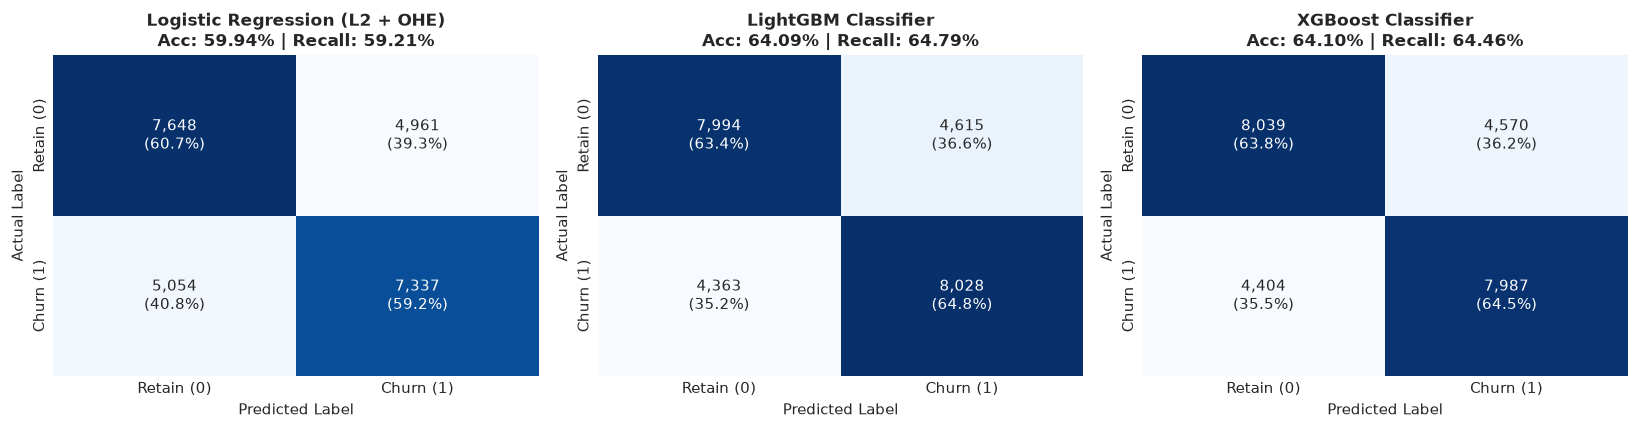

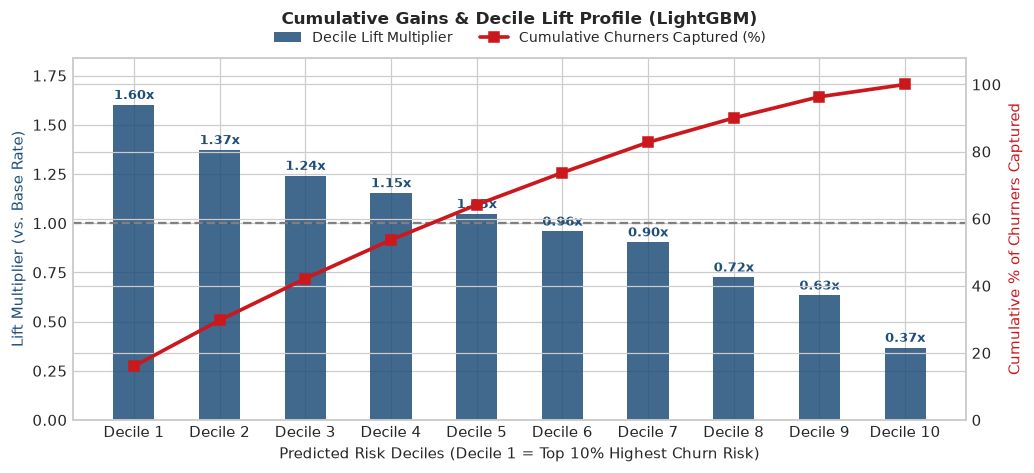

Targeting Efficiency: Decile 1 achieves 1.60x lift (79.4% churn rate); Deciles 1 & 2 capture 29.7% of all churners with a combined 1.49x lift.


In [10]:
# 6.3 Multi-Model Confusion Matrices (@ default p = 0.50) & Decile Lift (LightGBM)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
for ax, (name, probs) in zip(axes, models.items()):
    preds = (probs >= 0.5).astype(int)
    cm = confusion_matrix(y_test, preds)
    cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]
    annot = np.array([[f"{v:,}\n({pct:.1%})" for v, pct in zip(rv, rp)] for rv, rp in zip(cm, cm_norm)])
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Retain (0)', 'Churn (1)'], yticklabels=['Retain (0)', 'Churn (1)'])
    ax.set_title(f"{name}\nAcc: {accuracy_score(y_test, preds):.2%} | Recall: {recall_score(y_test, preds):.2%}")
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')
plt.tight_layout()
plt.show()

# Decile Lift & Cumulative Gains Profile (LightGBM)
eval_cohort = pd.DataFrame({
    'actual': y_test.values,
    'prob': lgb_probs,
    'rev_Mean': df_feat.loc[X_test_t.index, 'rev_Mean'].values
})

eval_cohort['decile'] = 9 - pd.qcut(eval_cohort['prob'], q=10, labels=False)

deciles = eval_cohort.groupby('decile').agg(
    total=('actual', 'count'),
    churners=('actual', 'sum'),
    mean_prob=('prob', 'mean'),
    avg_rev=('rev_Mean', 'mean')
).reset_index()

deciles['churn_rate'] = deciles['churners'] / deciles['total']
deciles['cum_churners'] = deciles['churners'].cumsum()
deciles['cum_capture_pct'] = (deciles['cum_churners'] / eval_cohort['actual'].sum()) * 100
deciles['lift'] = deciles['churn_rate'] / eval_cohort['actual'].mean()

fig, ax1 = plt.subplots(figsize=(9.5, 4.4))
ax2 = ax1.twinx()

bars = ax1.bar(deciles['decile'], deciles['lift'], color='#1f4e79', alpha=0.85, width=0.48, label='Decile Lift Multiplier')
line = ax2.plot(deciles['decile'], deciles['cum_capture_pct'], color='#cb181d', marker='s', linewidth=2.4, label='Cumulative Churners Captured (%)')

ax1.set_xticks(range(10))
ax1.set_xticklabels([f'Decile {i+1}' for i in range(10)])
ax1.set_xlabel('Predicted Risk Deciles (Decile 1 = Top 10% Highest Churn Risk)')
ax1.set_ylabel('Lift Multiplier (vs. Base Rate)', color='#1f4e79')
ax2.set_ylabel('Cumulative % of Churners Captured', color='#cb181d')
ax1.set_title('Cumulative Gains & Decile Lift Profile (LightGBM)', pad=22)
ax1.axhline(1.0, color='gray', linestyle='--')
ax1.set_ylim(0, max(deciles['lift']) * 1.15)
ax2.set_ylim(0, 108)

for i, l in enumerate(deciles['lift']):
    ax1.text(i, l + 0.03, f'{l:.2f}x', ha='center', fontsize=8.5, fontweight='bold', color='#1f4e79')

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='lower center', bbox_to_anchor=(0.5, 1.00), ncol=2, frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

d1_lift = deciles.loc[0, 'lift']
d12_capture = deciles.loc[1, 'cum_capture_pct']
d12_lift = (deciles.loc[0, 'churners'] + deciles.loc[1, 'churners']) / (deciles.loc[0, 'total'] + deciles.loc[1, 'total']) / eval_cohort['actual'].mean()
print(f"Targeting Efficiency: Decile 1 achieves {d1_lift:.2f}x lift ({deciles.loc[0, 'churn_rate']:.1%} churn rate); "
      f"Deciles 1 & 2 capture {d12_capture:.1f}% of all churners with a combined {d12_lift:.2f}x lift.")

## 7. Model Interpretability, Directionality, and Actionability

Tree split gain highlights which predictors carry the strongest overall signal, while comparing the Top Risk Decile against the Bottom Risk Decile clarifies directional impact and separates **actionable business levers** from **structural background context**.

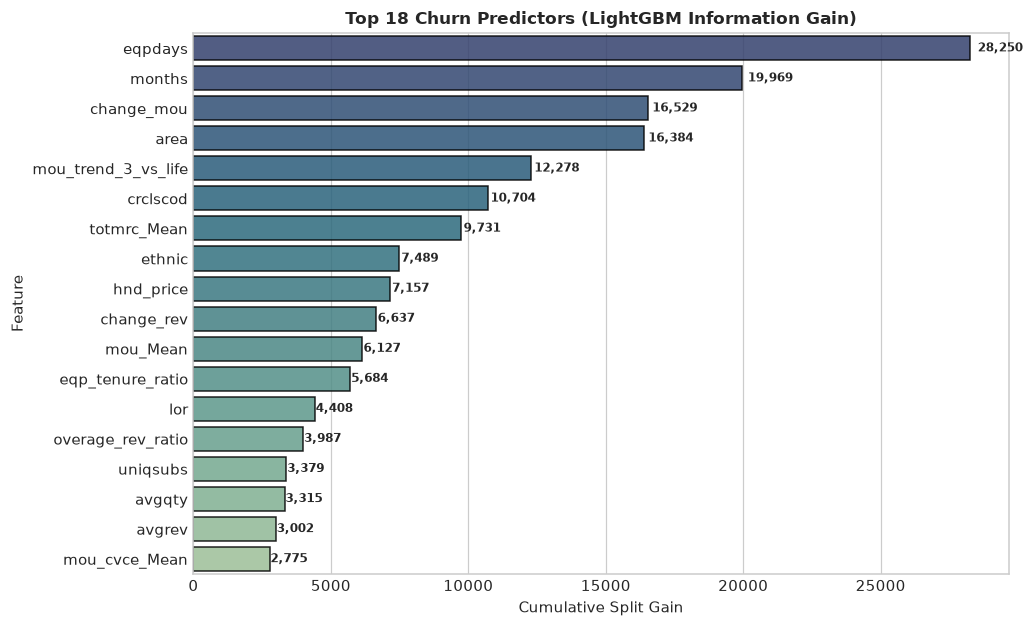

=== DIRECTIONAL & ACTIONABILITY AUDIT (TOP 10 NUMERIC DRIVERS) ===


,Feature,Top Risk Decile Mean,Low Risk Decile Mean,Empirical Direction,Business Lever
0,eqpdays,475.30,210.58,Higher -> Higher Risk,Actionable (Device Upgrade Offer)
1,months,18.44,15.16,Higher -> Higher Risk,Structural (Tenure)
2,change_mou,-73.84,31.64,Lower -> Higher Risk,Actionable (Early Disengagement Alert)
3,mou_trend_3_vs_life,0.66,1.12,Lower -> Higher Risk,Actionable (Usage Velocity Alert)
4,totmrc_Mean,38.85,53.42,Lower -> Higher Risk,Actionable (Plan Adjustment)
5,hnd_price,86.00,144.06,Lower -> Higher Risk,Contextual / Tiering
6,change_rev,1.14,-1.21,Higher -> Higher Risk,Behavioral / Telemetry Signal
7,mou_Mean,295.36,546.77,Lower -> Higher Risk,Behavioral / Telemetry Signal
8,eqp_tenure_ratio,0.86,0.66,Higher -> Higher Risk,Actionable (Upgrade Timing)
9,lor,5.41,7.27,Lower -> Higher Risk,Behavioral / Telemetry Signal


In [11]:
# 7.1 Top 18 Predictive Drivers (LightGBM Gain) + Directional Profile
gain_df = pd.DataFrame({
    'Feature': X_tree.columns,
    'Gain': lgb_model.booster_.feature_importance(importance_type='gain')
}).sort_values('Gain', ascending=False).head(18)

fig, ax = plt.subplots(figsize=(9.5, 5.8))
sns.barplot(data=gain_df, x='Gain', y='Feature', palette='crest_r', edgecolor='black', alpha=0.85, ax=ax)
ax.set_title('Top 18 Churn Predictors (LightGBM Information Gain)')
ax.set_xlabel('Cumulative Split Gain')
ax.set_ylabel('Feature')

for i, v in enumerate(gain_df['Gain']):
    ax.text(v * 1.01, i, f'{v:,.0f}', va='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

# Directional & Actionability Audit for top numeric drivers
actionable_map = {
    'eqpdays': 'Actionable (Device Upgrade Offer)',
    'eqp_tenure_ratio': 'Actionable (Upgrade Timing)',
    'hnd_price': 'Contextual / Tiering',
    'months': 'Structural (Tenure)',
    'totmrc_Mean': 'Actionable (Plan Adjustment)',
    'rev_Mean': 'Actionable (ARPU / VaR Weighting)',
    'change_mou': 'Actionable (Early Disengagement Alert)',
    'mou_trend_3_vs_6': 'Actionable (Usage Velocity Alert)',
    'mou_trend_3_vs_life': 'Actionable (Usage Velocity Alert)',
    'drop_failure_rate': 'Actionable (NetOps / Priority Care)',
    'overage_rev_ratio': 'Actionable (Zero Shock Plan Switch)',
    'custcare_rate': 'Actionable (Tier 3 Support Routing)',
    'crclscod': 'Structural (Credit Segment)'
}

top_numeric = [f for f in gain_df['Feature'] if f in num_cols][:10]
d1_mask = eval_cohort['decile'] == 0
d10_mask = eval_cohort['decile'] == 9
X_te_num = X_test_t.reset_index(drop=True)

dir_rows = []
for f in top_numeric:
    m_hi = X_te_num.loc[d1_mask, f].mean()
    m_lo = X_te_num.loc[d10_mask, f].mean()
    direction = 'Higher -> Higher Risk' if m_hi > m_lo else 'Lower -> Higher Risk'
    dir_rows.append({
        'Feature': f,
        'Top Risk Decile Mean': m_hi,
        'Low Risk Decile Mean': m_lo,
        'Empirical Direction': direction,
        'Business Lever': actionable_map.get(f, 'Behavioral / Telemetry Signal')
    })

dir_df = pd.DataFrame(dir_rows)
print("=== DIRECTIONAL & ACTIONABILITY AUDIT (TOP 10 NUMERIC DRIVERS) ===")
display(dir_df.style.format({'Top Risk Decile Mean': '{:,.2f}', 'Low Risk Decile Mean': '{:,.2f}'}))

## 8. Bayes Prior Calibration and Value at Risk Optimization

### 8.1 Correcting Retrospective Sampling Bias (Saerens et al., 2002)
Because the dataset uses **retrospective 50/50 sampling** ($\pi_{\text{sample}} = 49.56\%$), raw classifier probabilities $P_{\text{sample}}(y=1 \mid x)$ overstate real monthly churn risk ($\pi_{\text{real}} = 2.0\%$). Applying **Bayes prior shift adjustment** [4] restores calibrated 30 day production probabilities:
$$\text{odds}_{\text{real}}(x) = \text{odds}_{\text{sample}}(x) \times \frac{\pi_{\text{real}} / (1 - \pi_{\text{real}})}{\pi_{\text{sample}} / (1 - \pi_{\text{sample}})}, \qquad P_{\text{real}}(y=1 \mid x) = \frac{\text{odds}_{\text{real}}(x)}{1 + \text{odds}_{\text{real}}(x)}$$

### 8.2 Individualized Value at Risk vs. Uniform Thresholding
A subscriber paying **$120 per month** carries six times more margin exposure than one paying **$20 per month**. We model subscriber retention value over a conservative 24 month horizon at a 65% wireless gross margin:
$$V_i = \text{ARPU}_i \times 24 \times 0.65$$
We then compare two targeting policies tuned strictly on **five fold out of fold validation predictions** and evaluated out of sample on the holdout cohort weighted to the 2.0% real world monthly population:
1. **Policy A (Uniform Probability Cutoff $p^*_{\text{real}}$):** Target all subscribers whose calibrated monthly churn risk satisfies $P_{\text{real}}(\text{churn}_i) \ge p^*_{\text{real}}$.
2. **Policy B (Value at Risk Expected Value Rule $\text{EV}_i > 0$):** Target subscribers whose individualized expected retention payoff exceeds blended campaign cost ($C = \$15$, conservative campaign save rate $S = 25\%$):
$$\text{EV}_i = P_{\text{real}}(\text{churn}_i) \cdot S \cdot V_i - C > 0$$

=== OUT-OF-SAMPLE POLICY COMPARISON (100,000-SUBSCRIBER PRODUCTION BASE) ===


,Policy,Monthly Base Targeted (%),Targeted Accounts / Mo,Subscribers Saved / Mo,Gross Margin Saved / Yr ($),Campaign Cost / Yr ($),Net Margin Lift / Yr ($),Net Campaign ROI (%)
0,Policy A: Uniform Cutoff (p_real >= 0.070),1.06%,"1,064",31,"$249,338","$191,594","$57,744",30.1%
1,Policy B: Value-at-Risk Rule (EV_i > 0),3.42%,"3,422",43,"$1,031,825","$615,988","$415,837",67.5%


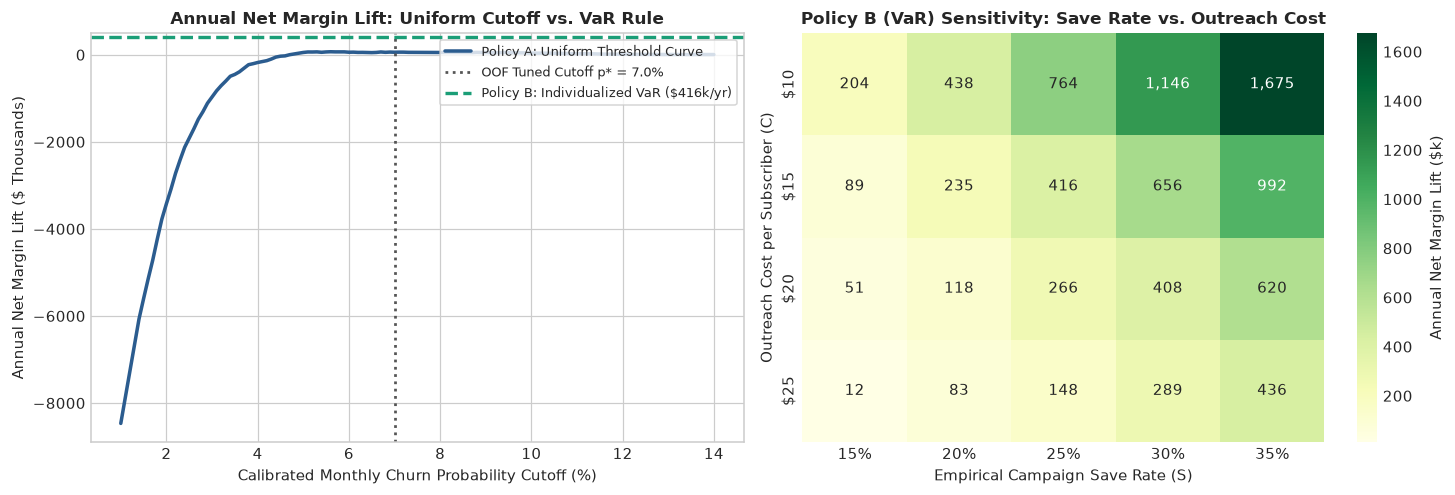

Policy B Breakeven Save Rate (at C=$15): 14.9% (Current base assumption S=25% provides a 10.1 pp safety margin).


In [12]:
# 8.1 Bayes Prior Calibration & Out-of-Fold Policy Optimization
PI_SAMPLE = float(y_train.mean())
PI_REAL = 0.020          # Real-world 30-day industry churn base rate (2.0%)
HORIZON_MONTHS = 24.0    # Conservative retention horizon
GROSS_MARGIN = 0.65      # Wireless service gross margin
C_OUTREACH = 15.0        # Blended digital/CRM retention cost per targeted user
S_SAVE_RATE = 0.25       # Conservative campaign save rate

def calibrate_prior(probs, pi_sample, pi_real):
    p_clip = np.clip(probs, 1e-6, 1.0 - 1e-6)
    odds_s = p_clip / (1.0 - p_clip)
    ratio = (pi_real / (1.0 - pi_real)) / (pi_sample / (1.0 - pi_sample))
    odds_r = odds_s * ratio
    return odds_r / (1.0 + odds_r)

# Calibrate OOF (train) and Test probabilities
p_real_oof = calibrate_prior(oof_probs['LightGBM Classifier'], PI_SAMPLE, PI_REAL)
p_real_test = calibrate_prior(lgb_probs, PI_SAMPLE, PI_REAL)

# Population importance weights to reflect 2.0% real-world base rate
w_oof = np.where(y_train.values == 1, PI_REAL / PI_SAMPLE, (1.0 - PI_REAL) / (1.0 - PI_SAMPLE))
w_oof = w_oof / w_oof.mean()

w_test = np.where(y_test.values == 1, PI_REAL / PI_SAMPLE, (1.0 - PI_REAL) / (1.0 - PI_SAMPLE))
w_test = w_test / w_test.mean()

# Individualized Customer Value V_i (clipped ARPU >= 0, median fallback if NaN)
rev_median = df_feat.loc[X_train_t.index, 'rev_Mean'].clip(lower=0).median()
rev_oof = df_feat.loc[X_train_t.index, 'rev_Mean'].clip(lower=0).fillna(rev_median).values
rev_test = df_feat.loc[X_test_t.index, 'rev_Mean'].clip(lower=0).fillna(rev_median).values

V_oof = rev_oof * HORIZON_MONTHS * GROSS_MARGIN
V_test = rev_test * HORIZON_MONTHS * GROSS_MARGIN

# Tune uniform threshold p*_real strictly on 5-Fold OOF predictions (scaled to 100k monthly base)
scale_oof_to_100k = 100000.0 / len(y_train)
scale_test_to_100k = 100000.0 / len(y_test)

th_grid = np.linspace(0.01, 0.14, 131)
oof_uniform_profits = []
for th in th_grid:
    tgt = (p_real_oof >= th)
    net_mo = scale_oof_to_100k * np.sum(w_oof * tgt * (y_train.values * S_SAVE_RATE * V_oof - C_OUTREACH))
    oof_uniform_profits.append(net_mo)

optimal_p_real = th_grid[int(np.argmax(oof_uniform_profits))]

# Evaluate both policies on the HELD-OUT TEST SET (scaled to 100k monthly subscribers)
def eval_policy(tgt_mask, label):
    targeted_pct = np.sum(w_test * tgt_mask) / np.sum(w_test) * 100.0
    targeted_mo = scale_test_to_100k * np.sum(w_test * tgt_mask)
    saved_mo = scale_test_to_100k * np.sum(w_test * tgt_mask * y_test.values * S_SAVE_RATE)
    gross_mo = scale_test_to_100k * np.sum(w_test * tgt_mask * y_test.values * S_SAVE_RATE * V_test)
    cost_mo = targeted_mo * C_OUTREACH
    net_mo = gross_mo - cost_mo
    roi_pct = (net_mo / cost_mo * 100.0) if cost_mo > 0 else 0.0
    return {
        'Policy': label,
        'Monthly Base Targeted (%)': targeted_pct,
        'Targeted Accounts / Mo': targeted_mo,
        'Subscribers Saved / Mo': saved_mo,
        'Gross Margin Saved / Yr ($)': gross_mo * 12.0,
        'Campaign Cost / Yr ($)': cost_mo * 12.0,
        'Net Margin Lift / Yr ($)': net_mo * 12.0,
        'Net Campaign ROI (%)': roi_pct
    }

tgt_uniform_test = (p_real_test >= optimal_p_real)
tgt_var_test = (p_real_test * S_SAVE_RATE * V_test > C_OUTREACH)

res_uniform = eval_policy(tgt_uniform_test, f'Policy A: Uniform Cutoff (p_real >= {optimal_p_real:.3f})')
res_var = eval_policy(tgt_var_test, 'Policy B: Value-at-Risk Rule (EV_i > 0)')

policy_df = pd.DataFrame([res_uniform, res_var])
print("=== OUT-OF-SAMPLE POLICY COMPARISON (100,000-SUBSCRIBER PRODUCTION BASE) ===")
display(policy_df.style.format({
    'Monthly Base Targeted (%)': '{:.2f}%',
    'Targeted Accounts / Mo': '{:,.0f}',
    'Subscribers Saved / Mo': '{:,.0f}',
    'Gross Margin Saved / Yr ($)': '${:,.0f}',
    'Campaign Cost / Yr ($)': '${:,.0f}',
    'Net Margin Lift / Yr ($)': '${:,.0f}',
    'Net Campaign ROI (%)': '{:.1f}%'
}).highlight_max(subset=['Net Margin Lift / Yr ($)', 'Net Campaign ROI (%)'], color='#c7e9c0'))

# Plot Test Profit Curve for Policy A vs Policy B Benchmark + Sensitivity Heatmap
test_uniform_annual = [
    12.0 * scale_test_to_100k * np.sum(w_test * (p_real_test >= th) * (y_test.values * S_SAVE_RATE * V_test - C_OUTREACH))
    for th in th_grid
]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

axes[0].plot(th_grid * 100, np.array(test_uniform_annual) / 1000.0, color='#2b5c8f', linewidth=2.3, label='Policy A: Uniform Threshold Curve')
axes[0].axvline(optimal_p_real * 100, color='#555555', linestyle=':', linewidth=1.8, label=f'OOF Tuned Cutoff p* = {optimal_p_real:.1%}')
axes[0].axhline(res_var['Net Margin Lift / Yr ($)'] / 1000.0, color='#1b9e77', linestyle='--', linewidth=2.2,
                label=f"Policy B: Individualized VaR (${res_var['Net Margin Lift / Yr ($)'] / 1000.0:,.0f}k/yr)")
axes[0].set_title('Annual Net Margin Lift: Uniform Cutoff vs. VaR Rule')
axes[0].set_xlabel('Calibrated Monthly Churn Probability Cutoff (%)')
axes[0].set_ylabel('Annual Net Margin Lift ($ Thousands)')
axes[0].legend(loc='upper right', fontsize=8.5, frameon=True)

# 2D Sensitivity Analysis on Policy B (Save Rate S vs Outreach Cost C)
s_grid = [0.15, 0.20, 0.25, 0.30, 0.35]
c_grid = [10.0, 15.0, 20.0, 25.0]
sens_matrix = np.zeros((len(c_grid), len(s_grid)))
for i, c_val in enumerate(c_grid):
    for j, s_val in enumerate(s_grid):
        t_mask = (p_real_test * s_val * V_test > c_val)
        net_yr = 12.0 * scale_test_to_100k * np.sum(w_test * t_mask * (y_test.values * s_val * V_test - c_val))
        sens_matrix[i, j] = net_yr / 1000.0

sns.heatmap(sens_matrix, annot=True, fmt=',.0f', cmap='YlGn', ax=axes[1],
            xticklabels=[f'{int(s*100)}%' for s in s_grid],
            yticklabels=[f'${int(c)}' for c in c_grid],
            cbar_kws={'label': 'Annual Net Margin Lift ($k)'})
axes[1].set_title('Policy B (VaR) Sensitivity: Save Rate vs. Outreach Cost')
axes[1].set_xlabel('Empirical Campaign Save Rate (S)')
axes[1].set_ylabel('Outreach Cost per Subscriber (C)')

plt.tight_layout()
plt.show()

# Compute exact break-even save rate for the Policy B targeted cohort
gross_at_100pct_save = 12.0 * scale_test_to_100k * np.sum(w_test * tgt_var_test * y_test.values * V_test)
breakeven_save_rate = res_var['Campaign Cost / Yr ($)'] / gross_at_100pct_save
print(f"Policy B Breakeven Save Rate (at C=${C_OUTREACH:.0f}): {breakeven_save_rate:.1%} "
      f"(Current base assumption S={S_SAVE_RATE:.0%} provides a {(S_SAVE_RATE - breakeven_save_rate)*100:.1f} pp safety margin).")

## 9. Prescriptive Next Best Action Playbooks

Rather than distributing blanket discounts across almost the entire customer base, **Policy B** isolates high Value at Risk accounts ($\text{EV}_i > 0$) and routes each subscriber to a root cause intervention:
1. **Hardware Obsolescence (`eqpdays > 365`):** Proactive 5G handset upgrade voucher and trade in subsidy.
2. **Bill Shock / Overage (`overage_rev_ratio > 0.15`):** Zero shock plan adjustment to eliminate recurring surcharge friction.
3. **Network Frustration (`drop_failure_rate > 0.05`):** Priority network routing and dedicated Tier 3 care outreach.
4. **General High Value at Risk Loyalty:** Targeted bonus data package to reinforce perceived value.
5. **Standard Care (No Outreach):** Subscribers with $\text{EV}_i \le 0$ remain untouched, preventing unnecessary retention expense.

In [13]:
# 9.1 Calibrated Next-Best-Action Matrix (Holdout Test Cohort & 100k Monthly Projection)
test_df = X_test_t.copy()
test_df['p_real_mo'] = p_real_test
test_df['rev_Mean'] = rev_test
test_df['V_clv'] = V_test
test_df['expected_var_ev'] = test_df['p_real_mo'] * S_SAVE_RATE * test_df['V_clv'] - C_OUTREACH
test_df['monthly_var'] = test_df['p_real_mo'] * test_df['rev_Mean']
test_df['pop_weight'] = w_test

def route_playbook(row):
    if row['expected_var_ev'] <= 0:
        return 'Standard Care (No Outreach)'
    elif row['eqpdays'] > 365:
        return '1. Handset Upgrade Subsidy (5G Voucher)'
    elif row['overage_rev_ratio'] > 0.15:
        return '2. Tariff Plan Adjustment (Zero Shock)'
    elif row['drop_failure_rate'] > 0.05:
        return '3. Network Priority & Concierge Care'
    else:
        return '4. Loyalty Value Bundle (Data Bonus)'

test_df['playbook'] = test_df.apply(route_playbook, axis=1)

nba_rows = []
for pb, grp in test_df.groupby('playbook'):
    w_sum = grp['pop_weight'].sum()
    share_pct = w_sum / test_df['pop_weight'].sum() * 100.0
    proj_100k_mo = scale_test_to_100k * w_sum
    w_mean_prob = np.average(grp['p_real_mo'], weights=grp['pop_weight'])
    w_mean_rev = np.average(grp['rev_Mean'], weights=grp['pop_weight'])
    proj_monthly_var = scale_test_to_100k * np.sum(grp['pop_weight'] * grp['monthly_var'])
    nba_rows.append({
        'Prescriptive Playbook': pb,
        'Base Share (%)': share_pct,
        '100k Base Subscribers / Mo': proj_100k_mo,
        'Calibrated Mo. Churn Prob': w_mean_prob,
        'Avg Monthly ARPU': w_mean_rev,
        'Monthly Revenue at Risk (100k Base)': proj_monthly_var
    })

nba_summary = pd.DataFrame(nba_rows).sort_values('Prescriptive Playbook')
print("=== CALIBRATED PRESCRIPTIVE NEXT BEST ACTION MATRIX (100K BASE / MONTH) ===")
display(nba_summary.style.format({
    'Base Share (%)': '{:.2f}%',
    '100k Base Subscribers / Mo': '{:,.0f}',
    'Calibrated Mo. Churn Prob': '{:.2%}',
    'Avg Monthly ARPU': '${:.2f}',
    'Monthly Revenue at Risk (100k Base)': '${:,.0f}'
}))

=== CALIBRATED PRESCRIPTIVE NEXT BEST ACTION MATRIX (100K BASE / MONTH) ===


,Prescriptive Playbook,Base Share (%),100k Base Subscribers / Mo,Calibrated Mo. Churn Prob,Avg Monthly ARPU,Monthly Revenue at Risk (100k Base)
0,1. Handset Upgrade Subsidy (5G Voucher),1.37%,"1,373",4.87%,$144.70,"$7,624"
1,2. Tariff Plan Adjustment (Zero Shock),1.66%,"1,657",3.75%,$187.06,"$9,930"
2,3. Network Priority & Concierge Care,0.28%,277,5.41%,$141.75,"$1,618"
3,4. Loyalty Value Bundle (Data Bonus),0.11%,115,7.66%,$115.37,$712
4,Standard Care (No Outreach),96.58%,"96,578",1.87%,$55.09,"$93,429"


## 10. Reconciled Enterprise Business Proposal, Risk Governance, and MLOps Architecture

Below we generate the executive pro forma financial summary programmatically from the calibrated holdout test outputs so that every operational and financial figure remains fully reconciled.

In [14]:
# 10.1 Programmatic Financial Reconciliation (100,000-Subscriber Base, 12-Month Horizon)
annual_baseline_churners = 100000.0 * PI_REAL * 12.0   # 24,000 churn events/year at 2.0%/mo
annual_targeted = res_var['Targeted Accounts / Mo'] * 12.0
annual_saved = res_var['Subscribers Saved / Mo'] * 12.0
annual_gross = res_var['Gross Margin Saved / Yr ($)']
annual_cost = res_var['Campaign Cost / Yr ($)']
annual_net = res_var['Net Margin Lift / Yr ($)']
net_roi = res_var['Net Campaign ROI (%)']

pro_forma = pd.DataFrame([
    ('Monthly Targeting Footprint', '0% (Reactive Inbound Only)', f"{res_var['Monthly Base Targeted (%)']:.2f}% ({res_var['Targeted Accounts / Mo']:,.0f} accts/mo)", 'Focused High VaR Outreach'),
    ('Annual Churn Events (100k Base @ 2%/mo)', f'{annual_baseline_churners:,.0f} departures / yr', f'{annual_baseline_churners - annual_saved:,.0f} departures / yr', f'{annual_saved:,.0f} Retained Accounts / yr'),
    ('Preserved 24 Mo Gross Margin', '$0', f'${annual_gross:,.0f} / yr', f'+${annual_gross:,.0f} Gross Margin'),
    ('Retention Campaign OpEx (@ $15/touch)', '$0', f'${annual_cost:,.0f} / yr', f'${-annual_cost:,.0f} OpEx Investment'),
    ('Net Enterprise Margin Lift', '$0', f'${annual_net:,.0f} / yr', f'+${annual_net:,.0f} Net Lift / yr'),
    ('Net Campaign ROI & Breakeven Save Rate', 'N/A', f'{net_roi:.1f}% Net ROI', f'Breakeven S = {breakeven_save_rate:.1%} (vs. {S_SAVE_RATE:.0%} base)')
], columns=['Financial / Operational Metric', 'Status Quo (Reactive)', 'Proactive VaR + NBA Engine', 'Net Impact'])

print("=== EXECUTIVE PRO FORMA BUSINESS CASE (RECONCILED TO TEST COHORT) ===")
display(pro_forma)

=== EXECUTIVE PRO FORMA BUSINESS CASE (RECONCILED TO TEST COHORT) ===


,Financial / Operational Metric,Status Quo (Reactive),Proactive VaR + NBA Engine,Net Impact
0,Monthly Targeting Footprint,0% (Reactive Inbound Only),"3.42% (3,422 accts/mo)",Focused High VaR Outreach
1,Annual Churn Events (100k Base @ 2%/mo),"24,000 departures / yr","23,480 departures / yr",520 Retained Accounts / yr
2,Preserved 24 Mo Gross Margin,$0,"$1,031,825 / yr","+$1,031,825 Gross Margin"
3,Retention Campaign OpEx (@ $15/touch),$0,"$615,988 / yr","$-615,988 OpEx Investment"
4,Net Enterprise Margin Lift,$0,"$415,837 / yr","+$415,837 Net Lift / yr"
5,Net Campaign ROI & Breakeven Save Rate,N/A,67.5% Net ROI,Breakeven S = 14.9% (vs. 25% base)


### 10.2 Production MLOps Architecture
The proposed deployment connects daily billing and call detail record (CDR) telemetry into five sequential stages:
1. **Daily Batch Ingestion:** Billing and network CDR tables enter an automated Airflow feature pipeline that computes three month and six month usage velocity, equipment tenure ratios, and normalized call drop rates.
2. **Model Scoring Container:** The regularized LightGBM service outputs raw sample propensity $P_{\text{sample}}(\text{churn})$.
3. **Bayes Prior Calibration Layer:** A deterministic odds adjustment maps $P_{\text{sample}}$ ($49.56\%$) onto the live monthly churn prior ($2.0\%$).
4. **Value at Risk Decision Engine:** Accounts satisfying $\text{EV}_i = P_{\text{real}, i} \cdot S \cdot V_i - C > 0$ (roughly $3.4\%$ of the monthly subscriber base) are prioritized for intervention.
5. **CRM and NetOps Routing:** Flagged accounts enter Salesforce or Amdocs campaigns across four targeted tracks: Handset Upgrade Subsidy (`eqpdays > 365`), Zero Shock Plan Adjustment (`overage_rev_ratio > 0.15`), VIP Network Priority (`drop_failure_rate > 0.05`), and Loyalty Data Bundle.

### 10.3 Risk Governance and Rollout Plan
| Risk | Why It Matters | Mitigation |
| :--- | :--- | :--- |
| **Subsidizing loyal stayers** | Unnecessary incentives dilute campaign return on investment. | Trigger outreach only when $\text{EV}_i > 0$ and verify incremental lift in a randomized A/B pilot. |
| **Calibration and prior drift** | Seasonal promotions or competitor offers shift the 2.0% monthly churn baseline. | Monitor Population Stability Index (PSI) monthly, update $\pi_{\text{real}}$ quarterly, and retrain if ROC-AUC drops below 0.66. |
| **Upstream ETL anomalies** | Negative offsets (`eqpdays < 0`, credit memos) distort engineered ratios. | Enforce schema validation checks and non negativity clipping inside the Airflow feature pipeline. |

1. **Months 1 to 2 (A/B Pilot):** Score 100% of subscribers and split VaR flagged accounts 80% treatment versus 20% holdout control. Advance only if empirical save rate beats the calculated breakeven threshold.
2. **Months 3 to 4 (CRM and CTI Integration):** Publish daily VaR scores and NBA playbooks into Salesforce or Amdocs CRM alongside inbound contact center priority routing.
3. **Months 5 onward (Continuous MLOps Governance):** Automate monthly PSI drift alerts, quarterly prior recalibration, and fairness checks across geographic `area` and credit `crclscod` segments.

### References
1. **Neslin, S. A., Gupta, S., Kamakura, W., Lu, J., & Mason, C. H. (2006).** *Defection Detection: Measuring and Understanding the Predictive Accuracy of Customer Churn Models.* Journal of Marketing Research, 43(2), pages 204 to 211.
2. **CTIA / FCC / Statista Wireless Industry Benchmarks (2024, 2025).** US mobile penetration exceeding 100% connection saturation and blended carrier monthly churn rates around 1.5% to 2.2%.
3. **Reichheld, F., & Schefter, P. (2000) / Bain & Company.** Retention versus acquisition cost economics in mature subscription and telecommunications markets.
4. **Saerens, M., Latinne, P., & Decaestecker, C. (2002).** *Adjusting the Outputs of a Classifier to New a Priori Probabilities: A Simple Procedure.* Neural Computation, 14(1), pages 21 to 41.
5. **Ke, G., et al. (2017).** *LightGBM: A Highly Efficient Gradient Boosting Decision Tree.* NeurIPS 2017; **Chen, T., & Guestrin, C. (2016).** *XGBoost: A Scalable Tree Boosting System.* KDD 2016.